In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix

In [51]:
data=pd.read_csv('loan_data.csv')

In [52]:
data.isnull().sum()

Loan_ID               0
Gender                5
Married               0
Dependents            8
Education             0
Self_Employed        21
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term     11
Credit_History       30
Property_Area         0
Loan_Status           0
dtype: int64

In [53]:
data["Gender"]=data["Gender"].fillna(data["Gender"].mode()[0])
data["Dependents"]=data["Dependents"].fillna(data["Dependents"].mode()[0])
data["Self_Employed"]=data["Self_Employed"].fillna(data["Self_Employed"].mode()[0])
data["Loan_Amount_Term"]=data["Loan_Amount_Term"].fillna(data["Loan_Amount_Term"].mode()[0])
data["Credit_History"]=data["Credit_History"].fillna(data["Credit_History"].mode()[0])

In [54]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            381 non-null    str    
 1   Gender             381 non-null    str    
 2   Married            381 non-null    str    
 3   Dependents         381 non-null    str    
 4   Education          381 non-null    str    
 5   Self_Employed      381 non-null    str    
 6   ApplicantIncome    381 non-null    int64  
 7   CoapplicantIncome  381 non-null    float64
 8   LoanAmount         381 non-null    float64
 9   Loan_Amount_Term   381 non-null    float64
 10  Credit_History     381 non-null    float64
 11  Property_Area      381 non-null    str    
 12  Loan_Status        381 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 38.8 KB


In [55]:
data.shape

(381, 13)

In [56]:
data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,381.000000,381.000000,381.000000,381.000000,381.000000
mean,3579.845144,1277.275381,104.986877,341.417323,0.850394
std,1419.813818,2340.818114,28.358464,67.625957,0.357154
min,150.000000,0.000000,9.000000,12.000000,0.000000
25%,2600.000000,0.000000,90.000000,360.000000,1.000000
50%,3333.000000,983.000000,110.000000,360.000000,1.000000
75%,4288.000000,2016.000000,127.000000,360.000000,1.000000
max,9703.000000,33837.000000,150.000000,480.000000,1.000000


In [57]:
data.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [58]:
le =LabelEncoder()

In [59]:
data["Gender"]=le.fit_transform(data["Gender"])
data["Married"]=le.fit_transform(data["Married"])
data["Loan_Status"]=le.fit_transform(data["Loan_Status"])
data["Self_Employed"] = le.fit_transform(data["Self_Employed"])
data["Education"] = le.fit_transform(data["Education"])

In [60]:
data.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,Rural,0
1,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,Urban,1
2,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,Urban,1
3,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,Urban,1
4,LP001013,1,1,0,1,0,2333,1516.0,95.0,360.0,1.0,Urban,1
5,LP001024,1,1,2,0,0,3200,700.0,70.0,360.0,1.0,Urban,1
6,LP001027,1,1,2,0,0,2500,1840.0,109.0,360.0,1.0,Urban,1
7,LP001029,1,0,0,0,0,1853,2840.0,114.0,360.0,1.0,Rural,0
8,LP001030,1,1,2,0,0,1299,1086.0,17.0,120.0,1.0,Urban,1
9,LP001032,1,0,0,0,0,4950,0.0,125.0,360.0,1.0,Urban,1


In [61]:
print(data["Gender"].unique())

[1 0]


In [62]:
pd.get_dummies(data, columns=["Property_Area"], drop_first=True)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Property_Area_Semiurban,Property_Area_Urban
0,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,0,False,False
1,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,1,False,True
2,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,1,False,True
3,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,1,False,True
4,LP001013,1,1,0,1,0,2333,1516.0,95.0,360.0,1.0,1,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
376,LP002953,1,1,3+,0,0,5703,0.0,128.0,360.0,1.0,1,False,True
377,LP002974,1,1,0,0,0,3232,1950.0,108.0,360.0,1.0,1,False,False
378,LP002978,0,0,0,0,0,2900,0.0,71.0,360.0,1.0,1,False,False
379,LP002979,1,1,3+,0,0,4106,0.0,40.0,180.0,1.0,1,False,False


In [63]:
data.head(109)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,1,1,1,0,0,4583,1508.0,128.0,360.0,1.0,Rural,0
1,LP001005,1,1,0,0,1,3000,0.0,66.0,360.0,1.0,Urban,1
2,LP001006,1,1,0,1,0,2583,2358.0,120.0,360.0,1.0,Urban,1
3,LP001008,1,0,0,0,0,6000,0.0,141.0,360.0,1.0,Urban,1
4,LP001013,1,1,0,1,0,2333,1516.0,95.0,360.0,1.0,Urban,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,LP001586,1,1,3+,1,0,3522,0.0,81.0,180.0,1.0,Rural,0
105,LP001603,1,1,0,1,1,4344,736.0,87.0,360.0,1.0,Semiurban,0
106,LP001606,1,1,0,0,0,3497,1964.0,116.0,360.0,1.0,Rural,1
107,LP001608,1,1,2,0,0,2045,1619.0,101.0,360.0,1.0,Rural,1


In [64]:
data["Property_Area"].unique

<bound method Series.unique of 0          Rural
1          Urban
2          Urban
3          Urban
4          Urban
         ...    
376        Urban
377        Rural
378        Rural
379        Rural
380    Semiurban
Name: Property_Area, Length: 381, dtype: str>

In [65]:
data = pd.get_dummies(
    data,
    columns=["Property_Area"],
    dtype=int
)

In [70]:
X=data.drop(columns="Loan_Status")
y=data["Loan_Status"]

In [69]:
data.columns

Index(['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed',
       'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Loan_Status',
       'Property_Area_Rural', 'Property_Area_Semiurban',
       'Property_Area_Urban'],
      dtype='str')

In [68]:
data.drop("Loan_ID", axis=1, inplace=True)

In [67]:
print(data["Dependents"].unique())
print(data["Dependents"].dtype)

[1 0 2 3]
object


In [66]:
data["Dependents"] = data["Dependents"].replace({
    "0": 0,
    "1": 1,
    "2": 2,
    "3+": 3
})

In [71]:
x_train, x_test, y_train,y_test= train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)

In [72]:
scale=StandardScaler()
x_train_scale=scale.fit_transform(x_train)
x_test_scale=scale.fit_transform(x_test)

In [73]:
lr=LogisticRegression()
lr.fit(x_train_scale,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [74]:
lr_pred=lr.predict(x_test)

c:\Users\SAI JEEVA S\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [75]:
print("Accuracy: ",accuracy_score(y_test,lr_pred))

Accuracy:  0.2857142857142857


In [76]:
cm=confusion_matrix(y_test,lr_pred)

In [77]:
print(cm)

[[22  0]
 [55  0]]


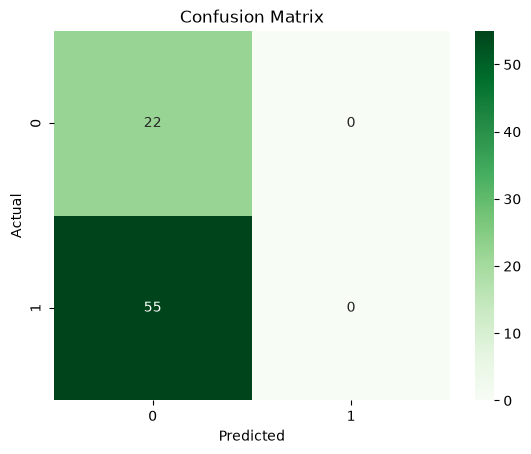

In [85]:
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()